## Cell 1: Feedforward neural network for building energy use

**Owner: Alex Mwamsindo**

> **Final selected configuration (from experiment `v06_g09`)**
> Inputs: 183 columns, the 175 base columns plus eight engineered features, with the five
> heavy-tailed area products log1p-transformed before scaling.
> Target: `log1p(MFBTU)`, converted back to kBtu for scoring.
> Network: hidden layers [32, 16] with ReLU, learning rate 0.0003, batch size 32,
> early stopping (patience 20) on a fixed monitor subset of the training rows.
> Selection: chosen by validation MAE through experiments v01–v07, recorded in
> `nn_experiment_log.csv` and the accompanying version notebooks.

#### Objectives
1. Build a reproducible feedforward neural network in TensorFlow/Keras to predict
   `MFBTU`, annual major-fuels consumption in kBtu.
2. Find the input configuration that gives the best validation performance by
   comparing the base feature set (175 columns) with the engineered set (183 columns),
   while keeping all 23 source variables.
3. Compare a raw `MFBTU` target with a `log1p(MFBTU)` target, scoring both in original kBtu.
4. Tune a small, justified set of hyperparameters (layers, units, learning rate,
   batch size, dropout, L2 regularization, early stopping) and check for overfitting
   with learning curves.
5. Evaluate the selected model across building subgroups, then score it once on
   the held-out test set.

#### Motivation
Commercial real estate acquisition analysts often need an energy estimate before
they have a building's utility history. A neural network can learn nonlinear
relationships and interactions between building size, operations, equipment and
climate that a linear model cannot represent directly. We test whether that
flexibility improves on the team's linear regression baseline and how it compares
with gradient boosting, without assuming it will.

#### Data
The team's processed 2018 CBECS file (`cbecs2018_processed.csv`, 6,357 buildings):
23 source variables with missing-value flags, survey-cap flags, one-hot encoded
categories, and eight candidate engineered features. We keep the project's fixed
70/15/15 split (4,449 / 954 / 954). Scaling is fitted on training rows only.
Validation MAE in kBtu is the main selection metric, as in the gradient boosting
notebook. The test set is used once, after model selection is complete.

In [41]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
# Imports, package versions, and reproducibility settings
import os
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

versions = {'Python': platform.python_version(), 'NumPy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'TensorFlow': tf.__version__,
            'GPUs visible': len(tf.config.list_physical_devices('GPU'))}
display(pd.Series(versions, name='Version').to_frame())

,Version
Python,3.13.18
NumPy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
TensorFlow,2.21.0
GPUs visible,0


In [43]:
# Load the processed data and run integrity checks
data_path = Path('/content/drive/MyDrive/Data/cbecs2018_processed.csv')
data = pd.read_csv(data_path)

ID_COLUMNS = ['PUBID', 'split', 'MFBTU']
NUMERIC = ['SQFT', 'FLCEILHT', 'WKHRS', 'NWKER', 'MONUSE', 'HDD65', 'CDD65', 'HEATP', 'COOLP', 'OCCUPYP']
ENGINEERED = ['log1p_SQFT', 'log1p_NWKER', 'workers_per_1000_sqft', 'weekly_floor_area_hours',
              'heated_floor_area', 'cooled_floor_area', 'heating_area_degree_days', 'cooling_area_degree_days']
all_features = [c for c in data.columns if c not in ID_COLUMNS]
binary_features = [c for c in all_features if c not in NUMERIC + ENGINEERED]
feature_sets = {'base': [c for c in all_features if c not in ENGINEERED], 'engineered': all_features}


assert data.shape == (6357, 186), data.shape
assert data.PUBID.is_unique and data.PUBID.notna().all()
assert data['split'].value_counts().to_dict() == {'train': 4449, 'validation': 954, 'test': 954}
assert len(feature_sets['base']) == 175 and len(feature_sets['engineered']) == 183

assert not set(ID_COLUMNS) & set(all_features), 'ID, split, or target found among features'
assert np.isfinite(data[all_features + ['MFBTU']].to_numpy(dtype=float)).all()
assert data.MFBTU.gt(0).all(), 'log1p target requires positive MFBTU'
assert data[binary_features].isin([0, 1]).all().all()
assert data.SQFT.le(1_000_000).all() and data.NWKER.le(5_000).all()


train = data.loc[data['split'].eq('train')].sort_values('PUBID').reset_index(drop=True)
validation = data.loc[data['split'].eq('validation')].sort_values('PUBID').reset_index(drop=True)
n_test = int(data['split'].eq('test').sum())

display(pd.DataFrame({'Rows': [len(train), len(validation), n_test]},
                     index=['train', 'validation', 'test (sealed)']))
display(pd.DataFrame({'Columns': [len(NUMERIC), len(ENGINEERED), len(binary_features),
                                  len(feature_sets['base']), len(feature_sets['engineered'])]},
                     index=['Numeric source', 'Engineered', 'Binary (flags + one-hot)', 'Base total', 'Engineered total']))
print(f"Training MFBTU: median {train.MFBTU.median():,.0f} kBtu, mean {train.MFBTU.mean():,.0f} kBtu")
print(f"Training skewness: raw {train.MFBTU.skew():.2f}, log1p {np.log1p(train.MFBTU).skew():.2f}")
print('All Stage 1 integrity checks passed.')

,Rows
train,4449
validation,954
test (sealed),954


,Columns
Numeric source,10
Engineered,8
Binary (flags + one-hot),165
Base total,175
Engineered total,183


Training MFBTU: median 4,397,988 kBtu, mean 15,868,331 kBtu
Training skewness: raw 7.69, log1p -0.42
All Stage 1 integrity checks passed.


## Model configuration

The configuration below was selected through seven experiment versions:

- **Target:** log1p outperformed the raw target on validation MAE (v01 vs v03).
- **Inputs:** engineered features with log-scaled area products were stable (v04) and
  outperformed base inputs once training settings were tuned (v06_g09 vs v07).
- **Settings:** a lower learning rate and a smaller network performed best among
  12 tested settings (v06).

Early stopping monitors a fixed 15% of the training rows (seed 42), never the
official validation set. The model is trained with three seeds, and results are
reported as the mean ± standard deviation. The test set remains sealed until the
final evaluation.

In [44]:
# Model configuration (selected in experiment v06_g09)
CONFIG = {
    'version': 'final_v06_g09',
    # Inputs
    'feature_set': 'engineered',      # 175 base columns + 8 engineered features
    'log_heavy_features': True,       # log1p the five heavy-tailed area products before scaling
    'drop_sources': [],
    'drop_columns': [],
    # Target
    'target': 'log1p',
    # Architecture
    'hidden_units': [32, 16],
    'activation': 'relu',
    'dropout': 0.0,
    'l2': 0.0,
    # Training
    'learning_rate': 3e-4,
    'batch_size': 32,
    'max_epochs': 300,
    'patience': 20,
    'monitor_fraction': 0.15,
    'seeds': [42, 43, 44],
}
display(pd.Series({k: str(v) for k, v in CONFIG.items()}, name='Setting').to_frame())

,Setting
version,final_v06_g09
feature_set,engineered
log_heavy_features,True
drop_sources,[]
drop_columns,[]
target,log1p
hidden_units,"[32, 16]"
activation,relu
dropout,0.0
l2,0.0


In [45]:
# Preparing inputs and target for this version
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

HEAVY_TAILED = ['weekly_floor_area_hours', 'heated_floor_area', 'cooled_floor_area',
                'heating_area_degree_days', 'cooling_area_degree_days']

# 1. Columns used in this version
feature_columns = [c for c in feature_sets[CONFIG['feature_set']]
                   if not any(c == s or c.startswith(s + '__') for s in CONFIG['drop_sources'])
                   and c not in CONFIG['drop_columns']]
continuous_columns = [c for c in feature_columns if c in NUMERIC + ENGINEERED]
binary_columns = [c for c in feature_columns if c not in continuous_columns]

# 2. Fixed early-stopping rows carved from training (identical in every version)
fit_idx, monitor_idx = train_test_split(train.index, test_size=CONFIG['monitor_fraction'], random_state=SEED)
fit, monitor = train.loc[sorted(fit_idx)], train.loc[sorted(monitor_idx)]
frames = {'fit': fit, 'monitor': monitor, 'validation': validation}

# 3. Inputs: optional log of heavy tails, then standardize continuous columns on fit rows only
def transform_inputs(frame):
    values = frame[feature_columns].astype(float).copy()
    if CONFIG['log_heavy_features']:
        cols = [c for c in HEAVY_TAILED if c in values]
        values[cols] = np.log1p(values[cols])
    return values

X_frames = {name: transform_inputs(f) for name, f in frames.items()}
scaler = StandardScaler().fit(X_frames['fit'][continuous_columns])
for name in X_frames:
    X_frames[name][continuous_columns] = scaler.transform(X_frames[name][continuous_columns])
X = {name: f.to_numpy(dtype='float32') for name, f in X_frames.items()}

# 4. Target: log1p or raw, then standardized with fit-row statistics
def to_fit_scale(mfbtu):
    mfbtu = np.asarray(mfbtu, dtype=float)
    return np.log1p(mfbtu) if CONFIG['target'] == 'log1p' else mfbtu

t_fit = to_fit_scale(fit.MFBTU)
y_mean, y_std = t_fit.mean(), t_fit.std()

def encode_target(mfbtu):
    return ((to_fit_scale(mfbtu) - y_mean) / y_std).astype('float32')

def decode_to_kbtu(z):
    """Network output -> kBtu, clipped at 0 (team convention)."""
    t = np.asarray(z, dtype=float).ravel() * y_std + y_mean
    return np.maximum(np.expm1(t) if CONFIG['target'] == 'log1p' else t, 0)

y = {name: encode_target(f.MFBTU) for name, f in frames.items()}
y_kbtu = {name: f.MFBTU.to_numpy(dtype=float) for name, f in frames.items()}

# 5. Checks
assert len(fit) + len(monitor) == len(train) and set(fit.PUBID).isdisjoint(monitor.PUBID)
assert not set(ID_COLUMNS) & set(feature_columns)
assert all(np.isfinite(a).all() for a in X.values()) and all(np.isfinite(a).all() for a in y.values())
assert np.allclose(X_frames['fit'][continuous_columns].mean(), 0, atol=1e-8)
assert np.allclose(X_frames['fit'][continuous_columns].std(ddof=0), 1, atol=1e-8)
assert np.allclose(decode_to_kbtu(y['fit']), y_kbtu['fit'], rtol=1e-4, atol=10), 'target round trip failed'

display(pd.DataFrame({'Rows': [len(f) for f in frames.values()], 'Columns': [X[n].shape[1] for n in X]},
                     index=['fit (trains weights)', 'monitor (early stopping)', 'validation (compares versions)']))
print(f"{CONFIG['version']}: {len(feature_columns)} inputs "
      f"({len(continuous_columns)} scaled continuous, {len(binary_columns)} binary 0/1)")
print(f"Target '{CONFIG['target']}' standardized with fit-row mean {y_mean:.4f}, std {y_std:.4f}")
print('Stage 2 checks passed.')

,Rows,Columns
fit (trains weights),3781,183
monitor (early stopping),668,183
validation (compares versions),954,183


final_v06_g09: 183 inputs (18 scaled continuous, 165 binary 0/1)
Target 'log1p' standardized with fit-row mean 14.9487, std 2.1135
Stage 2 checks passed.


## Build, train, and evaluate the network

The network is fully connected: inputs → hidden Dense layers with ReLU activation
(sizes set in `CONFIG`) → Dense(1, linear). It minimizes mean squared error on the standardized target (log1p or raw, as set in
`CONFIG`) with the Adam optimizer. Training stops when the monitor-set loss has not improved
for `patience` epochs, and the weights from the best epoch are restored.

Each version is trained with three seeds. We report validation MAE, RMSE, and R²
in kBtu as the mean ± standard deviation across seeds, so a later version only
counts as better if its gain is larger than this run-to-run variation.

In [46]:
# Model builder, metrics, and training function
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def build_model(n_inputs, cfg):
    reg = tf.keras.regularizers.l2(cfg['l2']) if cfg['l2'] > 0 else None
    model = tf.keras.Sequential([tf.keras.Input(shape=(n_inputs,))])
    for units in cfg['hidden_units']:
        model.add(tf.keras.layers.Dense(units, activation=cfg['activation'], kernel_regularizer=reg))
        if cfg['dropout'] > 0:
            model.add(tf.keras.layers.Dropout(cfg['dropout']))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=cfg['learning_rate']), loss='mse')
    return model

def kbtu_metrics(actual, predicted):
    return {'MAE_kBtu': mean_absolute_error(actual, predicted),
            'RMSE_kBtu': np.sqrt(mean_squared_error(actual, predicted)),
            'R2': r2_score(actual, predicted)}

def train_one_seed(seed, cfg):
    tf.keras.utils.set_random_seed(seed)
    model = build_model(X['fit'].shape[1], cfg)
    stopper = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=cfg['patience'],
                                               restore_best_weights=True)

    history = model.fit(X['fit'], y['fit'], validation_data=(X['monitor'], y['monitor']),
                        epochs=cfg['max_epochs'], batch_size=cfg['batch_size'],
                        shuffle=True, verbose=0, callbacks=[stopper])
    preds = {name: decode_to_kbtu(model.predict(X[name], verbose=0)) for name in X}
    return model, history.history, preds

build_model(X['fit'].shape[1], CONFIG).summary()

Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_75 (Dense)                │ (None, 32)             │         5,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_76 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_77 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,433 (25.13 KB)

 Trainable params: 6,433 (25.13 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
# Train with each seed and evaluate in kBtu
import time

runs, rows = {}, []
max_train_kbtu = train.MFBTU.max()
for seed in CONFIG['seeds']:
    start = time.time()
    model, hist, preds = train_one_seed(seed, CONFIG)
    best_epoch = int(np.argmin(hist['val_loss'])) + 1
    runs[seed] = {'model': model, 'history': hist, 'preds': preds, 'best_epoch': best_epoch}
    for name in ['fit', 'monitor', 'validation']:
        assert np.isfinite(preds[name]).all(), f'Non-finite predictions ({name}, seed {seed})'
        rows.append({'seed': seed, 'partition': name, **kbtu_metrics(y_kbtu[name], preds[name]),
                     'max_pred_kBtu': preds[name].max(),
                     'n_above_train_max': int((preds[name] > max_train_kbtu).sum())})
    print(f'Seed {seed}: ran {len(hist["loss"])} epochs, best epoch {best_epoch}, {time.time() - start:.0f}s')

seed_results = pd.DataFrame(rows)
summary = seed_results.groupby('partition', sort=False)[['MAE_kBtu', 'RMSE_kBtu', 'R2']].agg(['mean', 'std'])
display(seed_results.round(3))
display(summary.round(3))

Seed 42: ran 42 epochs, best epoch 22, 16s
Seed 43: ran 45 epochs, best epoch 25, 18s
Seed 44: ran 43 epochs, best epoch 23, 19s


,seed,partition,MAE_kBtu,RMSE_kBtu,R2,max_pred_kBtu,n_above_train_max
0,42,fit,4840085.610,1.737427e+07,0.789,4.544334e+08,0
1,42,monitor,5507763.790,2.214035e+07,0.706,2.625697e+08,0
2,42,validation,4968839.792,1.662098e+07,0.792,3.917701e+08,0
3,43,fit,4581100.926,1.692599e+07,0.799,4.037558e+08,0
4,43,monitor,5299441.426,1.511447e+07,0.863,4.679458e+08,0
5,43,validation,4825242.118,1.579732e+07,0.812,2.591458e+08,0
6,44,fit,4616103.711,1.671264e+07,0.804,3.553741e+08,0
7,44,monitor,5686690.657,2.073938e+07,0.742,2.923006e+08,0
8,44,validation,4839226.234,1.529452e+07,0.824,3.462205e+08,0


MAE_kBtu                 RMSE_kBtu                  R2       
                   mean         std          mean          std   mean    std
partition                                                                   
fit         4679096.749  140514.621  1.700430e+07   337695.715  0.797  0.008
monitor     5497965.291  193810.473  1.933140e+07  3718542.369  0.771  0.082
validation  4877769.381   79178.619  1.590427e+07   669664.225  0.810  0.016

In [48]:
# Record this version in the shared experiment log
import json
from datetime import datetime

LOG_PATH = data_path.parent / 'nn_experiment_log.csv'
entry = {'version': CONFIG['version'], 'timestamp': datetime.now().isoformat(timespec='seconds'),
         'n_inputs': len(feature_columns),
         'mean_best_epoch': float(np.mean([r['best_epoch'] for r in runs.values()]))}
for part, prefix in [('validation', 'val'), ('fit', 'fit')]:
    part_rows = seed_results[seed_results.partition.eq(part)]
    for metric in ['MAE_kBtu', 'RMSE_kBtu', 'R2']:
        entry[f'{prefix}_{metric}_mean'] = part_rows[metric].mean()
        entry[f'{prefix}_{metric}_std'] = part_rows[metric].std()
entry['config'] = json.dumps(CONFIG)

log = pd.read_csv(LOG_PATH) if LOG_PATH.exists() else pd.DataFrame()
if not log.empty:
    log = log[log['version'].ne(CONFIG['version'])]
log = pd.concat([log, pd.DataFrame([entry])], ignore_index=True)
log.to_csv(LOG_PATH, index=False)
display(log.drop(columns='config').round(3))
print(f'Logged {CONFIG["version"]} to {LOG_PATH}')

,version,timestamp,n_inputs,mean_best_epoch,val_MAE_kBtu_mean,val_MAE_kBtu_std,val_RMSE_kBtu_mean,val_RMSE_kBtu_std,val_R2_mean,val_R2_std,fit_MAE_kBtu_mean,fit_MAE_kBtu_std,fit_RMSE_kBtu_mean,fit_RMSE_kBtu_std,fit_R2_mean,fit_R2_std
0,v01_base_log,2026-11-14T23:53:01,175,8.000,5237602.429,181773.519,1.654535e+07,1852171.543,0.793,0.046,4937323.867,97952.862,1.814874e+07,608745.647,0.769,0.015
1,v02_engineered_log,2026-11-15T00:04:09,183,5.000,5207122.898,396135.435,1.703522e+07,402956.017,0.782,0.010,5177520.145,540436.732,1.972582e+07,3405880.332,0.722,0.098
2,v03_raw_target,2026-11-15T00:15:21,175,18.667,6251088.435,770918.247,1.507577e+07,722011.946,0.829,0.016,4227326.028,935832.973,9.244136e+06,2125515.051,0.938,0.026
3,v04_logscaled_products,2026-11-15T00:31:26,183,5.333,5106921.960,250008.974,1.695923e+07,1083877.022,0.783,0.028,4879411.206,339419.095,1.806301e+07,225813.979,0.771,0.006
4,v05_property_only,2026-11-15T00:53:18,117,8.000,5794869.399,50574.426,1.929038e+07,949415.679,0.720,0.028,5511318.660,41827.290,1.966145e+07,324123.936,0.729,0.009
5,v05_g01,2026-11-15T00:54:40,117,23.667,5909564.794,91016.838,1.963028e+07,436081.951,0.710,0.013,5394086.873,39892.157,1.927794e+07,429522.142,0.740,0.012
6,v05_g02,2026-11-15T00:56:35,117,68.333,5954768.259,12352.526,1.985283e+07,542161.538,0.704,0.016,5289815.884,133262.855,1.881394e+07,729735.170,0.752,0.019
7,v05_g03,2026-11-15T00:58:36,117,66.333,5856356.051,117002.494,2.043444e+07,369888.311,0.686,0.011,5381113.105,412788.235,1.992319e+07,1070716.156,0.721,0.029
8,v05_g04,2026-11-15T00:59:44,117,26.000,5851139.680,113457.529,1.934360e+07,348822.823,0.719,0.010,5292647.770,65966.476,1.901730e+07,528572.596,0.746,0.014
9,v05_g05,2026-11-15T01:01:21,117,50.000,5717045.978,124690.727,1.946162e+07,918498.547,0.715,0.027,4896951.709,111499.554,1.810453e+07,779241.704,0.770,0.020


Logged final_v06_g09 to /content/drive/MyDrive/Data/nn_experiment_log.csv


In [49]:
# Reproducibility check: the final model must match its experiment-log entry
logged = pd.read_csv(LOG_PATH).set_index('version').loc['v06_g09']
final_val = seed_results[seed_results.partition.eq('validation')]
assert np.isclose(final_val.MAE_kBtu.mean(), logged.val_MAE_kBtu_mean, rtol=1e-6), \
    f'Final MAE {final_val.MAE_kBtu.mean():,.0f} differs from logged v06_g09 {logged.val_MAE_kBtu_mean:,.0f}'
print(f'Reproduced v06_g09: validation MAE {final_val.MAE_kBtu.mean():,.0f} kBtu '
      f'(logged {logged.val_MAE_kBtu_mean:,.0f}); best epochs {[r["best_epoch"] for r in runs.values()]}')

Reproduced v06_g09: validation MAE 4,877,769 kBtu (logged 4,877,769); best epochs [22, 25, 23]


## Final model: validation results

Retraining the selected configuration reproduced experiment `v06_g09` exactly
(validation MAE 4,877,769 kBtu, best epochs 22, 25, and 23), confirming that the
final model is the one selected during experimentation.

Across three seeds, validation MAE was 4.88M ± 0.08M kBtu, RMSE 15.9M ± 0.7M kBtu,
and R² 0.810 ± 0.016. Training (fit) MAE was 4.68M, about 4% lower than validation,
indicating a small generalization gap. No predictions exceeded the largest training
building. Because this configuration was selected from multiple validation
comparisons, these validation scores are likely slightly optimistic; the held-out
test evaluation provides the unbiased estimate.

## Learning curves and overfitting

The curves compare the original settings (v04: learning rate 0.001, hidden layers
[64, 32]) with the final model (learning rate 0.0003, hidden layers [32, 16]) on the
same inputs and target. Blue lines show training loss on the fit rows; dashed orange
lines show loss on the monitor rows used for early stopping. Dots mark the epoch whose
weights were restored. One line per seed.

Overfitting appears as training loss continuing to fall while monitor loss stops
improving or rises. Early stopping guards against it by restoring the best-monitor
epoch. Note that Keras reports training loss as an average over each epoch while the
weights are still changing, so early-epoch training loss is slightly overstated
relative to monitor loss.

v04 reproduced: validation MAE 5,106,922 kBtu (logged 5,106,922)


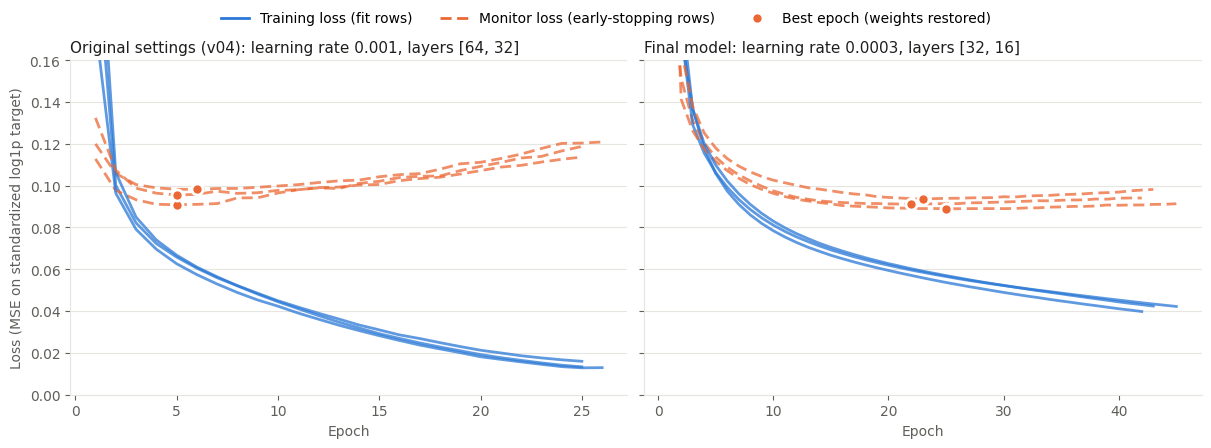

,model,seed,best_epoch,epochs_run,train_loss_at_best,monitor_loss_at_best,monitor_loss_at_end,gap_at_best,rise_after_best
0,v04 settings,42,5,25,0.0658,0.0908,0.1187,0.0250,0.0279
1,v04 settings,43,6,26,0.0574,0.0982,0.1209,0.0407,0.0227
2,v04 settings,44,5,25,0.0667,0.0955,0.1136,0.0287,0.0182
3,Final model,42,22,42,0.0570,0.0911,0.0941,0.0341,0.0030
4,Final model,43,25,45,0.0565,0.0889,0.0913,0.0324,0.0024
5,Final model,44,23,43,0.0591,0.0937,0.0982,0.0346,0.0045


,best_epoch,train_loss_at_best,monitor_loss_at_best,gap_at_best,rise_after_best
model,,,,,
v04 settings,5.3333,0.0633,0.0948,0.0315,0.0229
Final model,23.3333,0.0576,0.0912,0.0337,0.0033


Figure saved to /content/drive/MyDrive/Data/figures/nn_learning_curves.png


In [50]:
# Learning curves: original settings (v04) vs final model
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

v04_cfg = {**CONFIG, 'hidden_units': [64, 32], 'learning_rate': 1e-3, 'version': 'v04_curves'}
v04_runs = {}
for seed in CONFIG['seeds']:
    _, hist, preds = train_one_seed(seed, v04_cfg)
    v04_runs[seed] = {'history': hist, 'best_epoch': int(np.argmin(hist['val_loss'])) + 1,
                      'val_MAE': mean_absolute_error(y_kbtu['validation'], preds['validation'])}
v04_mae = np.mean([r['val_MAE'] for r in v04_runs.values()])
logged_v04 = pd.read_csv(LOG_PATH).set_index('version').loc['v04_logscaled_products', 'val_MAE_kBtu_mean']
assert np.isclose(v04_mae, logged_v04, rtol=1e-6), f'v04 retrain MAE {v04_mae:,.0f} differs from logged {logged_v04:,.0f}'
print(f'v04 reproduced: validation MAE {v04_mae:,.0f} kBtu (logged {logged_v04:,.0f})')

TRAIN_COLOR, MONITOR_COLOR, GRID, INK = '#2a78d6', '#eb6834', '#e6e5e0', '#5f5e5a'
panels = [('Original settings (v04): learning rate 0.001, layers [64, 32]', v04_runs),
          ('Final model: learning rate 0.0003, layers [32, 16]', runs)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True, constrained_layout=True)
for ax, (title, panel_runs) in zip(axes, panels):
    for seed, r in panel_runs.items():
        h, b = r['history'], r['best_epoch']
        epochs = np.arange(1, len(h['loss']) + 1)
        ax.plot(epochs, h['loss'], color=TRAIN_COLOR, lw=2, alpha=0.75)
        ax.plot(epochs, h['val_loss'], color=MONITOR_COLOR, lw=2, alpha=0.75, ls=(0, (4, 2)))
        ax.plot(b, h['val_loss'][b - 1], 'o', ms=8, color=MONITOR_COLOR, mec='white', mew=2, zorder=3)
    ax.set_title(title, fontsize=11, loc='left', color='#1f1f1d')
    ax.set_xlabel('Epoch', color=INK)
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color(GRID)
axes[0].set_ylabel('Loss (MSE on standardized log1p target)', color=INK)
axes[0].set_ylim(0, 0.16)   # zoom to the informative range; first-epoch losses (up to ~0.75) fall above the axis
handles = [Line2D([], [], color=TRAIN_COLOR, lw=2, label='Training loss (fit rows)'),
           Line2D([], [], color=MONITOR_COLOR, lw=2, ls=(0, (4, 2)), label='Monitor loss (early-stopping rows)'),
           Line2D([], [], color=MONITOR_COLOR, marker='o', ms=8, mec='white', mew=2, ls='none',
                  label='Best epoch (weights restored)')]
fig.legend(handles=handles, loc='outside upper center', ncol=3, frameon=False)

FIG_DIR = data_path.parent / 'figures'
FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / 'nn_learning_curves.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

rows = []
for label, panel_runs in [('v04 settings', v04_runs), ('Final model', runs)]:
    for seed, r in panel_runs.items():
        h, b = r['history'], r['best_epoch']
        rows.append({'model': label, 'seed': seed, 'best_epoch': b, 'epochs_run': len(h['loss']),
                     'train_loss_at_best': h['loss'][b - 1], 'monitor_loss_at_best': h['val_loss'][b - 1],
                     'monitor_loss_at_end': h['val_loss'][-1]})
curve_table = pd.DataFrame(rows)
curve_table['gap_at_best'] = curve_table.monitor_loss_at_best - curve_table.train_loss_at_best
curve_table['rise_after_best'] = curve_table.monitor_loss_at_end - curve_table.monitor_loss_at_best
display(curve_table.round(4))
display(curve_table.groupby('model', sort=False)[['best_epoch', 'train_loss_at_best', 'monitor_loss_at_best',
                                                 'gap_at_best', 'rise_after_best']].mean().round(4))
print(f'Figure saved to {FIG_DIR / "nn_learning_curves.png"}')

## Learning curves: findings

With the original settings (learning rate 0.001), monitor loss reached its minimum
at epochs 5–6 and then rose by 0.023 on average over the next 20 epochs while
training loss kept falling, a clear sign of overfitting. With the final settings
(learning rate 0.0003), the minimum came at epochs 22–25, and monitor loss rose
only 0.003 afterwards, a plateau rather than a reversal.

The gap between monitor and training loss at the restored epoch was similar for
both (0.032 and 0.034), so early stopping already limited overfitting under the
original settings. The benefit of tuning is that the slower learning rate reached a
lower monitor loss (0.0912 vs 0.0948) before overfitting began, which corresponds
to the validation MAE improvement from 5.11M to 4.88M kBtu. Dropout and L2
regularization did not improve on this (v06), indicating that the learning rate,
not model capacity, was the main source of overfitting.

## Subgroup evaluation

Validation performance is broken down by building type (`PBA`), floor-area quartile,
and the survey's 1M sq ft area cap. Building types with fewer than 30 validation
buildings are pooled into one group. Area quartile cut points come from the training
rows, so the validation set does not define its own bins.

Each metric is computed separately for the three seed models and then averaged.
Because consumption varies by orders of magnitude, MAE in kBtu mostly reflects building
size. The median absolute percentage error shows relative accuracy within each group,
and the median signed percentage error shows systematic bias (negative means the model
underpredicts).

In [51]:
# Subgroup evaluation on the validation set
PBA_NAMES = {1: 'Vacant', 2: 'Office', 4: 'Laboratory', 5: 'Nonrefrigerated warehouse', 6: 'Food sales',
             7: 'Public order and safety', 8: 'Outpatient health care', 11: 'Refrigerated warehouse',
             12: 'Religious worship', 13: 'Public assembly', 14: 'Education', 15: 'Food service',
             16: 'Inpatient health care', 17: 'Nursing', 18: 'Lodging', 23: 'Strip shopping center',
             24: 'Enclosed mall', 25: 'Retail other than mall', 26: 'Service', 91: 'Other'}
MIN_GROUP = 30
actual = y_kbtu['validation']

# 1. Building type: decode the one-hot PBA columns; pool types with fewer than MIN_GROUP buildings
pba_cols = [c for c in validation.columns if c.startswith('PBA__code_')]
assert validation[pba_cols].sum(axis=1).eq(1).all(), 'each building should have exactly one PBA code'
pba_code = validation[pba_cols].idxmax(axis=1).str.replace('PBA__code_', '', regex=False).astype(int)
type_counts = pba_code.value_counts()
OTHER = f'Other types (each n < {MIN_GROUP})'
type_group = pba_code.map(lambda c: PBA_NAMES[c] if type_counts[c] >= MIN_GROUP else OTHER)
type_order = [PBA_NAMES[c] for c in type_counts.index if type_counts[c] >= MIN_GROUP] + [OTHER]

# 2. Size: quartiles of floor area, with cut points taken from the TRAINING rows
q = train.SQFT.quantile([0.25, 0.5, 0.75]).to_numpy()
size_order = [f'Q1: up to {q[0]:,.0f} sq ft', f'Q2: {q[0]:,.0f}–{q[1]:,.0f} sq ft',
              f'Q3: {q[1]:,.0f}–{q[2]:,.0f} sq ft', f'Q4: over {q[2]:,.0f} sq ft']
size_group = pd.cut(validation.SQFT, [-np.inf, *q, np.inf], labels=size_order).astype(str)

# 3. Survey cap: buildings whose true area exceeds 1M sq ft (reported as capped)
cap_order = ['1M sq ft or less', 'Over 1M sq ft (capped)']
cap_group = validation['SQFT__above_1m'].eq(1).map({False: cap_order[0], True: cap_order[1]})

def subgroup_table(groups, order):
    """Metrics per group, computed for each seed and then averaged across seeds."""
    groups = np.asarray(groups)
    rows = []
    for name, mask in [('All validation buildings', np.ones(len(actual), bool))] + [(g, groups == g) for g in order]:
        a = actual[mask]
        per_seed = pd.DataFrame([{
            'MAE': mean_absolute_error(a, r['preds']['validation'][mask]),
            'abs_pct': np.median(np.abs(r['preds']['validation'][mask] - a) / a) * 100,
            'signed_pct': np.median((r['preds']['validation'][mask] - a) / a) * 100} for r in runs.values()])
        rows.append({'group': name, 'n': int(mask.sum()),
                     'median actual (M kBtu)': np.median(a) / 1e6,
                     'MAE (M kBtu)': per_seed.MAE.mean() / 1e6,
                     'MAE seed std (M)': per_seed.MAE.std() / 1e6,
                     'median abs % error': per_seed.abs_pct.mean(),
                     'median signed % error': per_seed.signed_pct.mean()})
    return pd.DataFrame(rows).set_index('group')

tables = {'Building type (PBA)': subgroup_table(type_group, type_order),
          'Floor-area quartile': subgroup_table(size_group, size_order),
          'Survey area cap': subgroup_table(cap_group, cap_order)}
RESULTS_DIR = data_path.parent / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
for title, table in tables.items():
    print(title)
    display(table.round(2))
    table.to_csv(RESULTS_DIR / f'nn_subgroups_{title.split()[0].lower()}.csv')
print('Negative signed % error = underprediction. Tables saved to', RESULTS_DIR)

Building type (PBA)


,n,median actual (M kBtu),MAE (M kBtu),MAE seed std (M),median abs % error,median signed % error
group,,,,,,
All validation buildings,954,3.37,4.88,0.08,33.99,1.94
Office,186,4.45,4.77,0.15,27.52,1.98
Education,148,6.39,3.70,0.13,30.99,7.12
Nonrefrigerated warehouse,116,1.64,2.89,0.21,47.12,1.22
Public assembly,69,1.91,4.04,0.71,38.29,-7.72
Service,61,0.25,1.48,0.56,44.33,-6.30
Retail other than mall,53,2.98,1.83,0.17,29.01,9.31
Lodging,53,7.33,4.55,0.38,33.79,19.90
Inpatient health care,45,82.67,31.96,1.89,26.76,-1.63


Floor-area quartile


,n,median actual (M kBtu),MAE (M kBtu),MAE seed std (M),median abs % error,median signed % error
group,,,,,,
All validation buildings,954,3.37,4.88,0.08,33.99,1.94
"Q1: up to 12,000 sq ft",252,0.22,0.18,0.00,41.96,6.11
"Q2: 12,000–75,000 sq ft",250,2.04,1.18,0.05,39.61,2.76
"Q3: 75,000–210,000 sq ft",229,8.86,3.45,0.02,30.03,1.83
"Q4: over 210,000 sq ft",223,24.70,15.80,0.27,26.95,-0.37


Survey area cap


,n,median actual (M kBtu),MAE (M kBtu),MAE seed std (M),median abs % error,median signed % error
group,,,,,,
All validation buildings,954,3.37,4.88,0.08,33.99,1.94
1M sq ft or less,939,3.21,3.94,0.12,33.95,2.32
Over 1M sq ft (capped),15,89.49,63.48,10.39,30.11,-19.50


Negative signed % error = underprediction. Tables saved to /content/drive/MyDrive/Data/results


## Subgroup evaluation: findings

Across all validation buildings, the median absolute percentage error was 34% and the
median signed error was +1.9%, so the model is not systematically biased overall.
Relative accuracy improved with building size: the median error fell from 42% in the
smallest floor-area quartile to 27% in the largest.

The 15 buildings above the survey's 1M sq ft cap were underpredicted by about 20%,
likely because their capped floor area hides their true size. These 1.6% of
validation buildings account for roughly 20% of total absolute error, explaining
why RMSE and R² are sensitive to a few buildings. With only 15 buildings, this
result is descriptive.

By building type, relative accuracy was best for inpatient health care (27%), office
(28%), and retail (29%), and weakest for nonrefrigerated warehouses (47%), service
(44%), and religious worship (42%). Lodging was overpredicted (+20%), while outpatient
health care (−16%) and food service (−12%) were underpredicted; these groups have
32–53 buildings, so the biases are suggestive rather than conclusive.

## Final test evaluation

The selected model is scored once on the 954 held-out test buildings, which were not
used for training, early stopping, tuning, or feature selection. The test inputs use
the same transformations and the scaler fitted on the training (fit) rows. Results are
the mean ± standard deviation across the three seed models. The model is not changed
after this evaluation.

Team results are copied from the linear regression and gradient boosting notebooks
(same splits, kBtu metrics). They are single fitted models, while the network's figures
average three seeds.

In [52]:
# Final test evaluation
RUN_FINAL_TEST = True

if RUN_FINAL_TEST:
    # 1. Prepare test inputs exactly like the other partitions (scaler fitted on fit rows only)
    test = data.loc[data['split'].eq('test')].sort_values('PUBID').reset_index(drop=True)
    assert len(test) == 954 and set(test.PUBID).isdisjoint(train.PUBID) and set(test.PUBID).isdisjoint(validation.PUBID)
    X_test_frame = transform_inputs(test)
    X_test_frame[continuous_columns] = scaler.transform(X_test_frame[continuous_columns])
    X_test = X_test_frame.to_numpy(dtype='float32')
    y_test = test.MFBTU.to_numpy(dtype=float)
    assert np.isfinite(X_test).all()

    # 2. Score each seed model
    test_rows, test_preds = [], {}
    for seed, r in runs.items():
        p = decode_to_kbtu(r['model'].predict(X_test, verbose=0))
        assert np.isfinite(p).all()
        test_preds[seed] = p
        test_rows.append({'seed': seed, **kbtu_metrics(y_test, p),
                          'n_above_train_max': int((p > max_train_kbtu).sum())})
    test_results = pd.DataFrame(test_rows)
    display(test_results.round(3))

    # 3. Validation vs test for the network
    val_rows = seed_results[seed_results.partition.eq('validation')]
    nn_summary = pd.DataFrame({
        'Validation mean': val_rows[['MAE_kBtu', 'RMSE_kBtu', 'R2']].mean(),
        'Validation std': val_rows[['MAE_kBtu', 'RMSE_kBtu', 'R2']].std(),
        'Test mean': test_results[['MAE_kBtu', 'RMSE_kBtu', 'R2']].mean(),
        'Test std': test_results[['MAE_kBtu', 'RMSE_kBtu', 'R2']].std()})
    display(nn_summary.round(3))

    # 4. Team comparison (MAE and RMSE in millions of kBtu)
    nn_test = test_results[['MAE_kBtu', 'RMSE_kBtu', 'R2']].mean()
    comparison = pd.DataFrame([
        {'model': 'Linear regression (Isabella)', 'val_MAE_M': 9.420, 'val_R2': 0.697,
         'test_MAE_M': 11.453, 'test_RMSE_M': 28.174, 'test_R2': 0.550},
        {'model': 'Gradient boosting (Yera)', 'val_MAE_M': 4.421, 'val_R2': 0.826,
         'test_MAE_M': 5.972, 'test_RMSE_M': 22.423, 'test_R2': 0.715},
        {'model': 'Neural network (Alex, 3-seed mean)', 'val_MAE_M': val_rows.MAE_kBtu.mean() / 1e6,
         'val_R2': val_rows.R2.mean(), 'test_MAE_M': nn_test.MAE_kBtu / 1e6,
         'test_RMSE_M': nn_test.RMSE_kBtu / 1e6, 'test_R2': nn_test.R2}]).set_index('model')
    display(comparison.round(3))

    # 5. Save
    test_results.to_csv(RESULTS_DIR / 'FINAL_nn_test_metrics.csv', index=False)
    pd.DataFrame({'PUBID': test.PUBID, 'actual_MFBTU': y_test,
                  **{f'pred_seed_{s}': p for s, p in test_preds.items()}}).to_csv(
        RESULTS_DIR / 'FINAL_nn_test_predictions.csv', index=False)
    comparison.to_csv(RESULTS_DIR / 'FINAL_team_model_comparison.csv')
    print('Saved test metrics, predictions, and team comparison to', RESULTS_DIR)
else:
    print('Final test scoring skipped.')

,seed,MAE_kBtu,RMSE_kBtu,R2,n_above_train_max
0,42,6152803.800,2.242458e+07,0.715,0
1,43,6173385.087,2.259782e+07,0.710,0
2,44,6533227.003,2.413825e+07,0.669,0


,Validation mean,Validation std,Test mean,Test std
MAE_kBtu,4.877769e+06,79178.619,6.286472e+06,213943.765
RMSE_kBtu,1.590427e+07,669664.225,2.305355e+07,943360.018
R2,8.100000e-01,0.016,6.980000e-01,0.025


,val_MAE_M,val_R2,test_MAE_M,test_RMSE_M,test_R2
model,,,,,
Linear regression (Isabella),9.420,0.697,11.453,28.174,0.550
Gradient boosting (Yera),4.421,0.826,5.972,22.423,0.715
"Neural network (Alex, 3-seed mean)",4.878,0.810,6.286,23.054,0.698


Saved test metrics, predictions, and team comparison to /content/drive/MyDrive/Data/results


## Final test evaluation: findings

On the 954 held-out test buildings, the network achieved MAE 6.29M ± 0.21M kBtu,
RMSE 23.1M ± 0.9M kBtu, and R² 0.698 ± 0.025 (three seeds). It outperformed linear
regression (MAE 11.45M, R² 0.550) by 45% on MAE but trailed gradient boosting
(MAE 5.97M, RMSE 22.4M, R² 0.715) on all three metrics, by about 5% on MAE.

All three models scored lower on test than on validation (MAE +22% for linear
regression, +35% for gradient boosting, +29% for the network). Because the decline is
shared across algorithms, it most likely reflects a harder test partition, in which a
few very large buildings dominate the variance, rather than overfitting by any single
model to the validation set.

## Conclusions and limitations

**Conclusions.**
- A feedforward network substantially outperforms linear regression, even when it
  uses only property-level inputs (v05), but gradient boosting remains the strongest
  model on this tabular dataset.
- The log1p target improves MAE at the cost of RMSE and R², a trade-off that also
  appears in gradient boosting and therefore stems from the target transform.
- Engineered features help only when their heavy tails are log-transformed and the
  learning rate is tuned; the learning rate, not model capacity, was the main source of
  overfitting.
- Relative accuracy improves with building size, and buildings above the survey's
  1M sq ft cap are underpredicted by about 20%.

**Limitations.**
- Metrics are unweighted; CBECS survey weights (`FINALWT`) were not used.
- A single fixed validation split was used for all selection decisions, so validation
  scores are somewhat optimistic; the test set gives the unbiased estimate.
- Reserving 15% of training rows for early stopping reduces the network's training
  data relative to the other models.
- R² and RMSE are dominated by a handful of very large buildings, and capped floor
  area hides the true size of the largest ones.
- The property-only classification and the 0.3M kBtu noise threshold reflect our
  judgment, and three seeds give only a rough estimate of run-to-run variation.